# DuckDB Processing for full.csv Dataset
Loading and analyzing the full.csv file using DuckDB with the specified schema.

In [ ]:
import duckdb
import os

# Paths are relative to this notebook's directory
# (tertiary-repos/kuhlenkamp_et_al), where the upstream full.csv is pulled in.
db_path = "full_data.duckdb"
csv_path = "full.csv"

conn = duckdb.connect(db_path)

try:
    conn.execute(f"""
        CREATE OR REPLACE TABLE full_data AS
        SELECT *
        FROM read_csv_auto('{csv_path}', ignore_errors=true)
    """)

    # Add derived columns: duration and cold-start flag
    conn.execute("""
        CREATE OR REPLACE TABLE full_data_enriched AS
        SELECT
            *,
            REnd - RStart AS run_duration,
            CASE
                WHEN ROW_NUMBER() OVER (PARTITION BY CId ORDER BY RStart) = 1 THEN TRUE
                ELSE FALSE
            END AS cold
        FROM full_data
    """)

    print(f"DuckDB database created at: {db_path}")
    print("Table 'full_data_enriched' includes run_duration and cold columns.")
finally:
    conn.close()

DuckDB database created at: kuhlenkamp_et_al/full_data.duckdb
Table 'full_data_enriched' includes run_duration and cold columns.


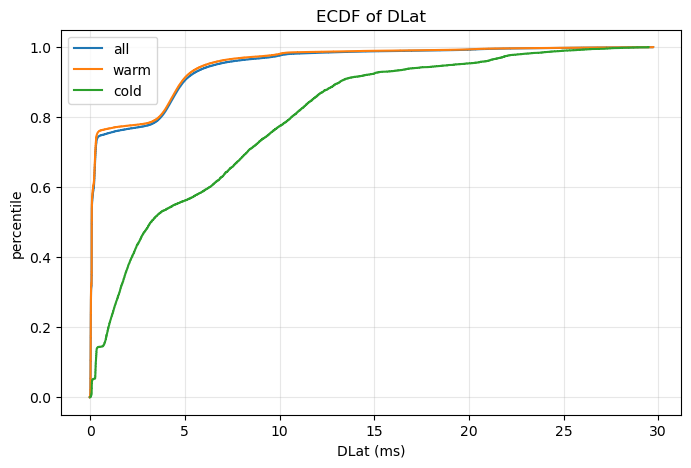

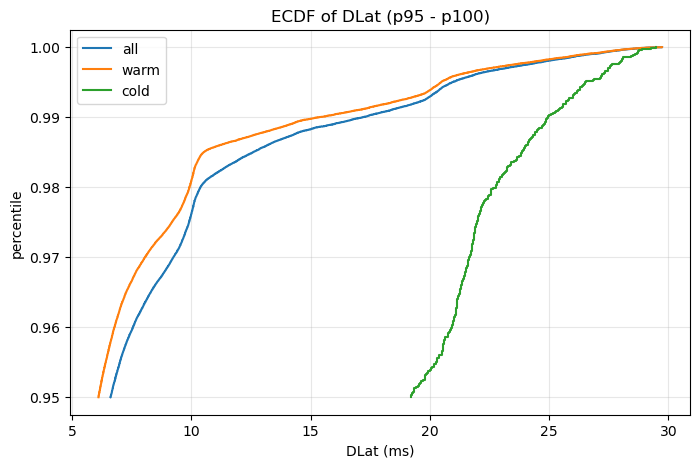

In [19]:
# ECDF plots for DLat
import duckdb
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

db_path = "full_data.duckdb"

conn = duckdb.connect(db_path)

try:
    plot_df = conn.execute("""
        SELECT DLat, cold
        FROM full_data_enriched
        WHERE DLat IS NOT NULL AND RSuccessed = TRUE
    """).df()

    # DLat is numeric (ms precision)
    plot_df["dlat_ms"] = pd.to_numeric(plot_df["DLat"], errors="coerce")
    plot_df = plot_df[np.isfinite(plot_df["dlat_ms"])].copy()

    all_calls = plot_df["dlat_ms"].to_numpy()
    warm_calls = plot_df.loc[plot_df["cold"] == False, "dlat_ms"].to_numpy()
    cold_calls = plot_df.loc[plot_df["cold"] == True, "dlat_ms"].to_numpy()

    def ecdf(values):
        values = np.sort(values)
        y = np.arange(1, len(values) + 1) / len(values)
        return values, y

    # ECDF (full range)
    plt.figure(figsize=(8, 5))
    for series, label in [
        (all_calls, "all"),
        (warm_calls, "warm"),
        (cold_calls, "cold"),
    ]:
        if len(series) == 0:
            continue
        x, y = ecdf(series)
        plt.step(x, y, where="post", label=label)

    plt.xlabel("DLat (ms)")
    plt.ylabel("percentile")
    plt.title("ECDF of DLat")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

    # ECDF (zoomed p95 to p100)
    plt.figure(figsize=(8, 5))
    for series, label in [
        (all_calls, "all"),
        (warm_calls, "warm"),
        (cold_calls, "cold"),
    ]:
        if len(series) == 0:
            continue
        x, y = ecdf(series)
        mask = y >= 0.95
        plt.step(x[mask], y[mask], where="post", label=label)

    plt.xlabel("DLat (ms)")
    plt.ylabel("percentile")
    plt.title("ECDF of DLat (p95 - p100)")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()
finally:
    conn.close()

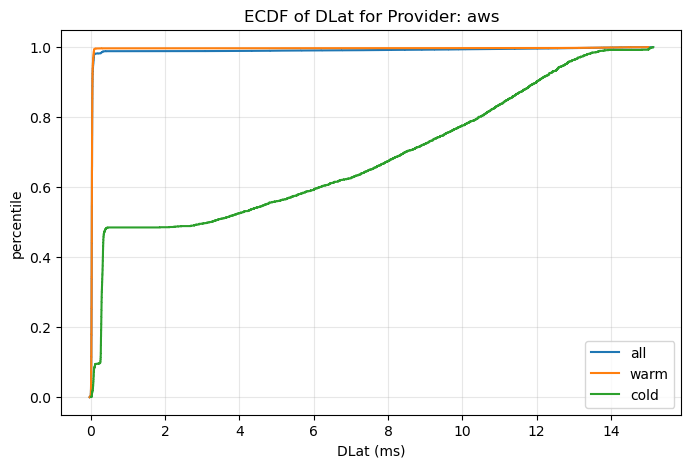

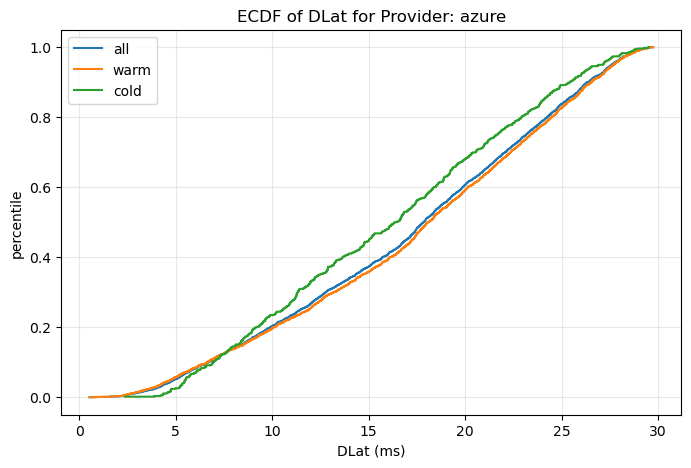

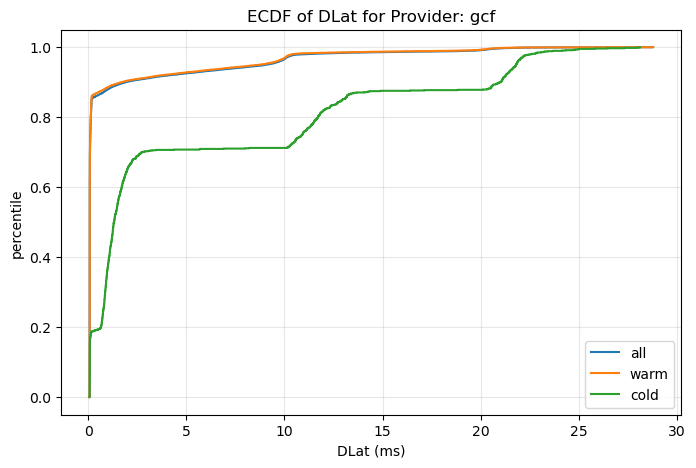

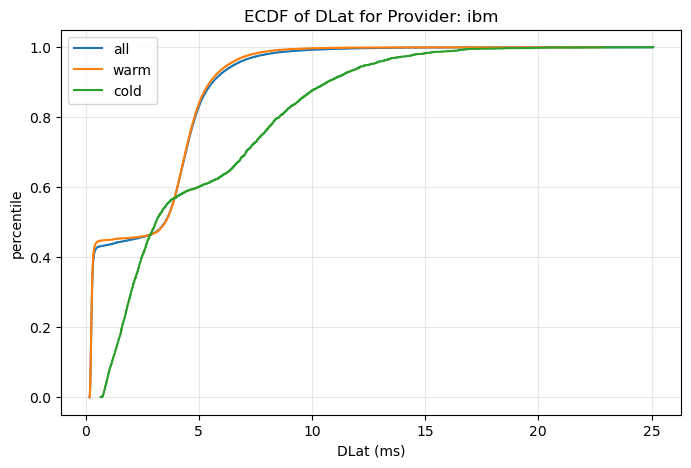

In [20]:
# ECDFs by Provider with cold vs warm (DLat)
import duckdb
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

db_path = "full_data.duckdb"

conn = duckdb.connect(db_path)

try:
    plot_df = conn.execute("""
        SELECT DLat, Provider, cold
        FROM full_data_enriched
        WHERE DLat IS NOT NULL AND Provider IS NOT NULL AND cold IS NOT NULL AND RSuccessed = TRUE
    """).df()

    plot_df["dlat_ms"] = pd.to_numeric(plot_df["DLat"], errors="coerce")
    plot_df = plot_df[np.isfinite(plot_df["dlat_ms"])].copy()

    def ecdf(values):
        values = np.sort(values)
        y = np.arange(1, len(values) + 1) / len(values)
        return values, y

    for provider in sorted(plot_df["Provider"].unique()):
        provider_df = plot_df.loc[plot_df["Provider"] == provider]
        all_calls = provider_df["dlat_ms"].to_numpy()
        warm_calls = provider_df.loc[provider_df["cold"] == False, "dlat_ms"].to_numpy()
        cold_calls = provider_df.loc[provider_df["cold"] == True, "dlat_ms"].to_numpy()

        plt.figure(figsize=(8, 5))
        for series, label in [
            (all_calls, "all"),
            (warm_calls, "warm"),
            (cold_calls, "cold"),
        ]:
            if len(series) == 0:
                continue
            x, y = ecdf(series)
            plt.step(x, y, where="post", label=label)

        plt.xlabel("DLat (ms)")
        plt.ylabel("percentile")
        plt.title(f"ECDF of DLat for Provider: {provider}")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.show()
finally:
    conn.close()

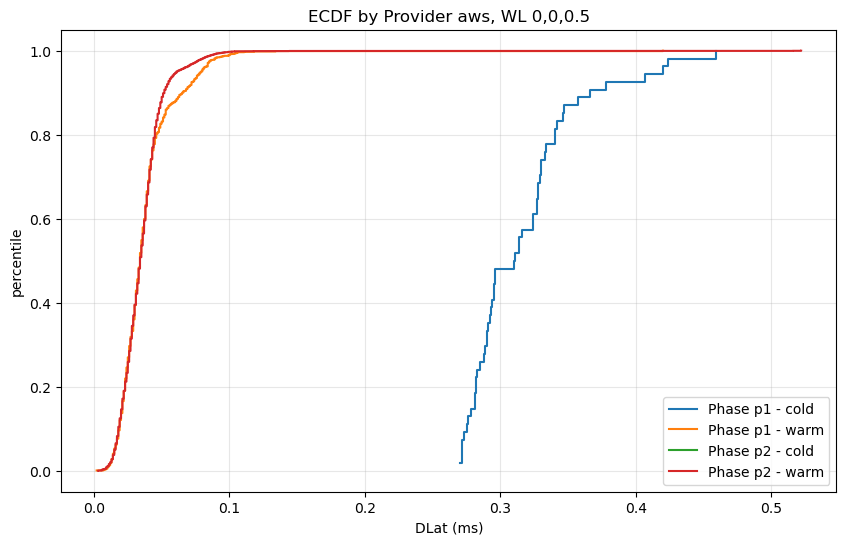

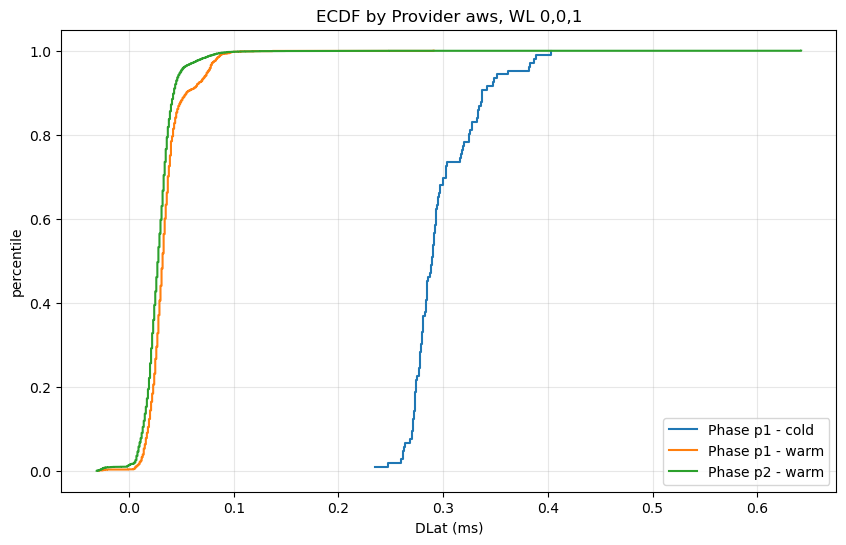

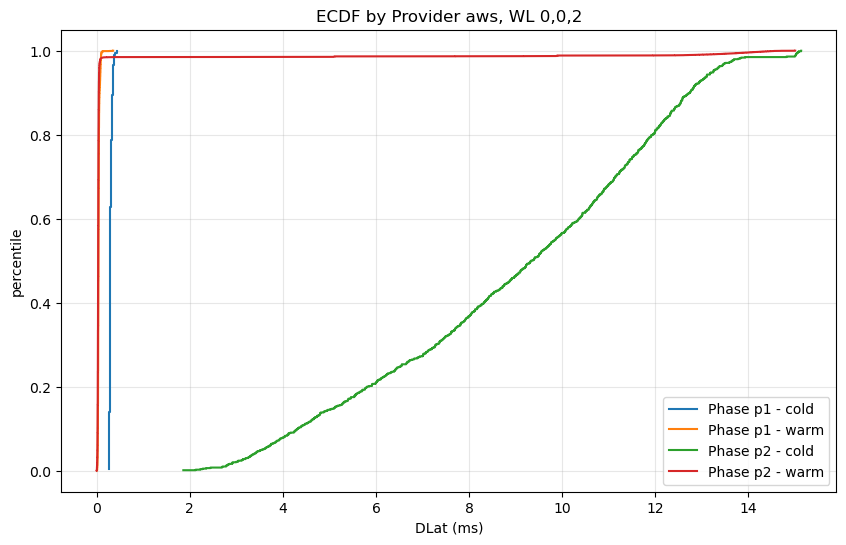

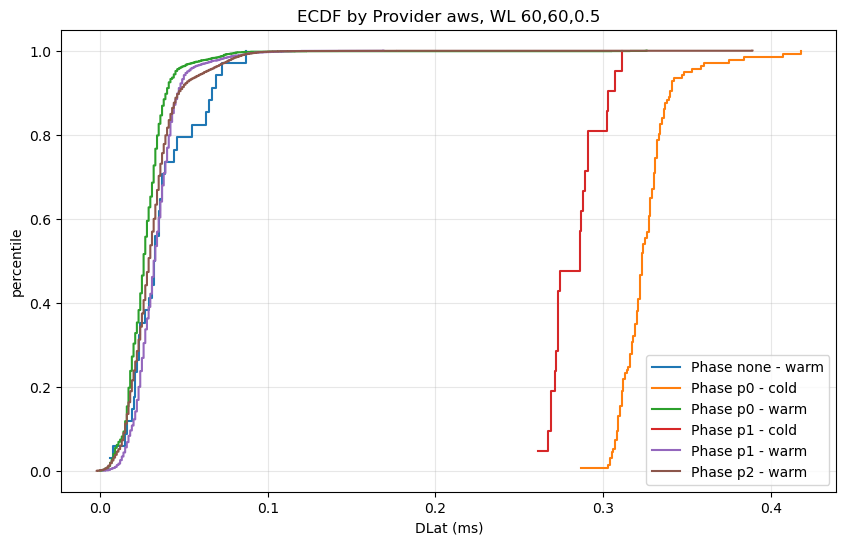

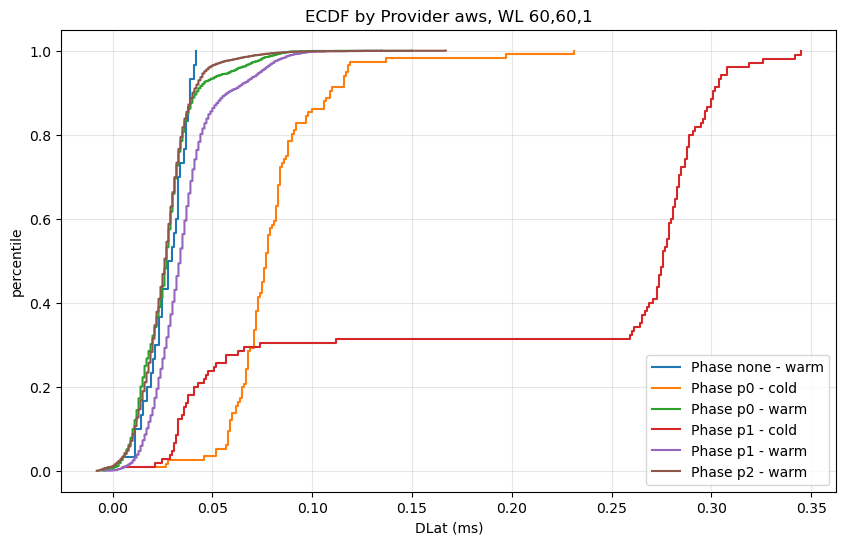

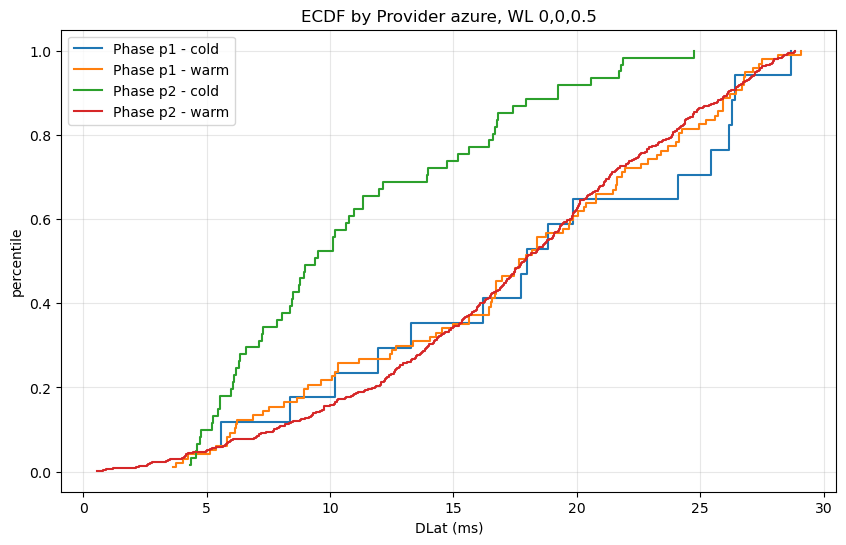

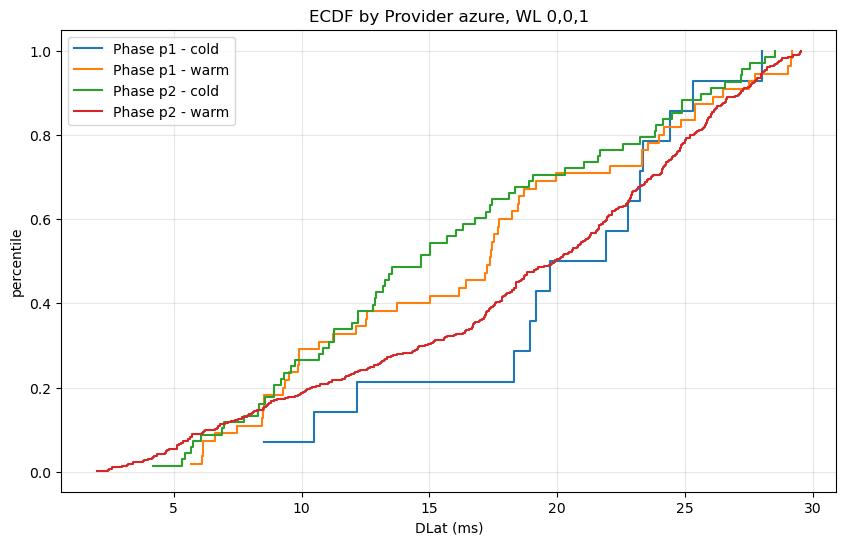

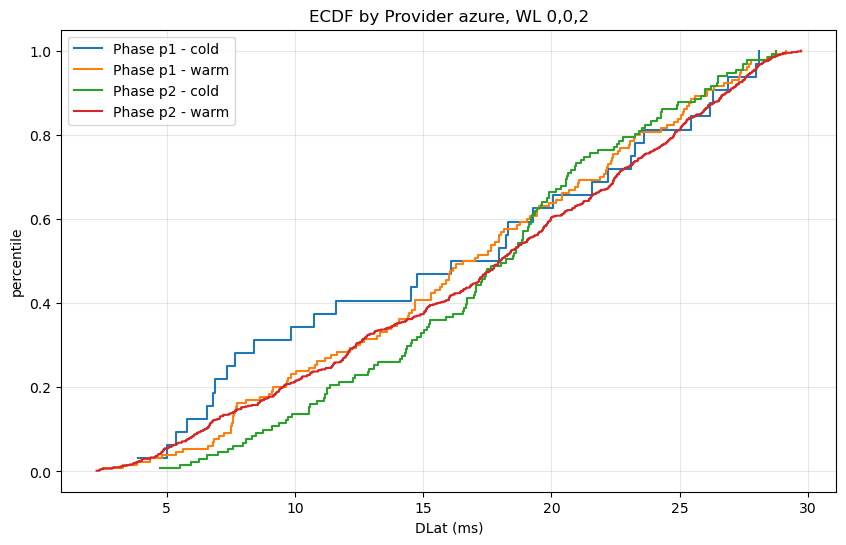

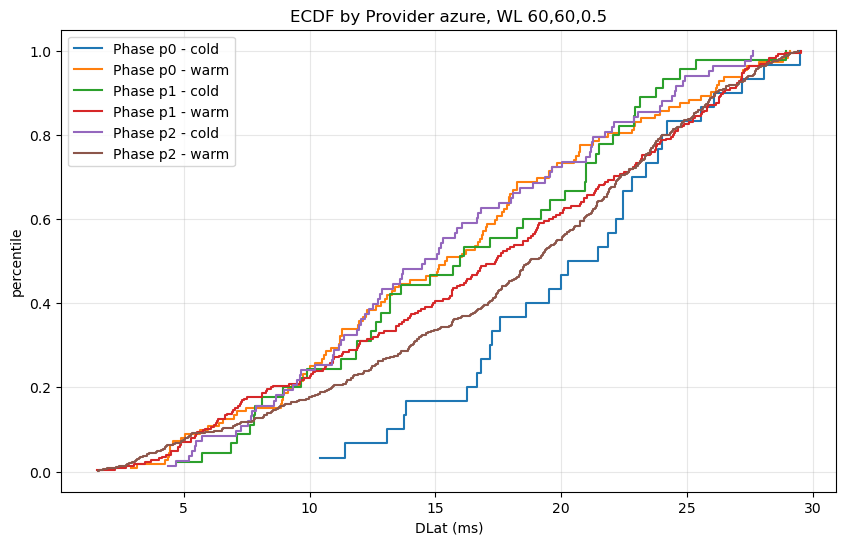

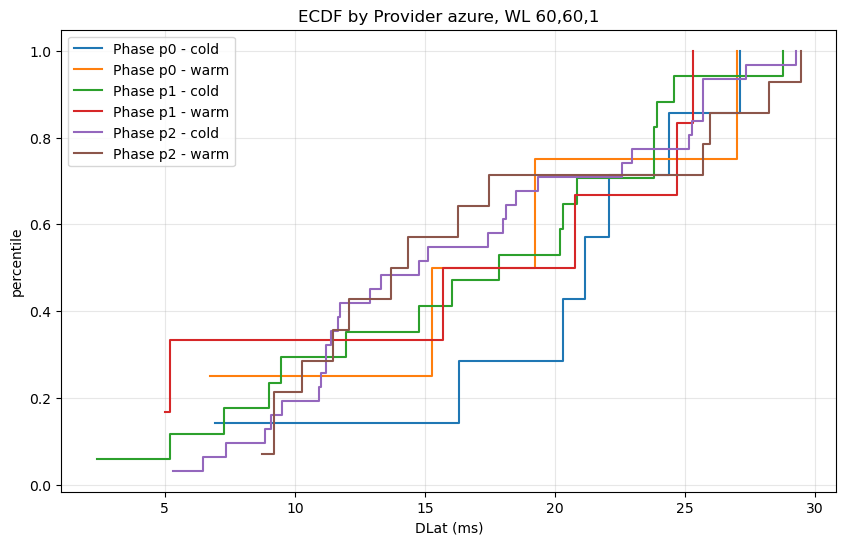

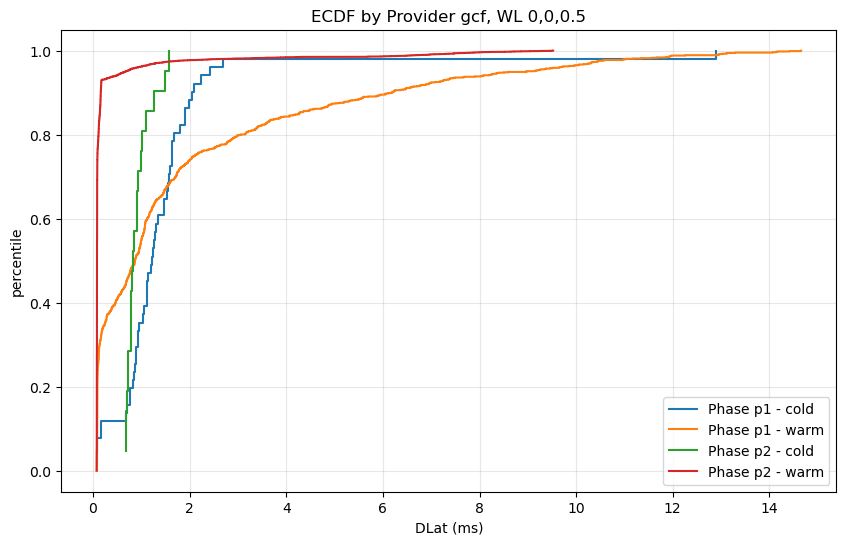

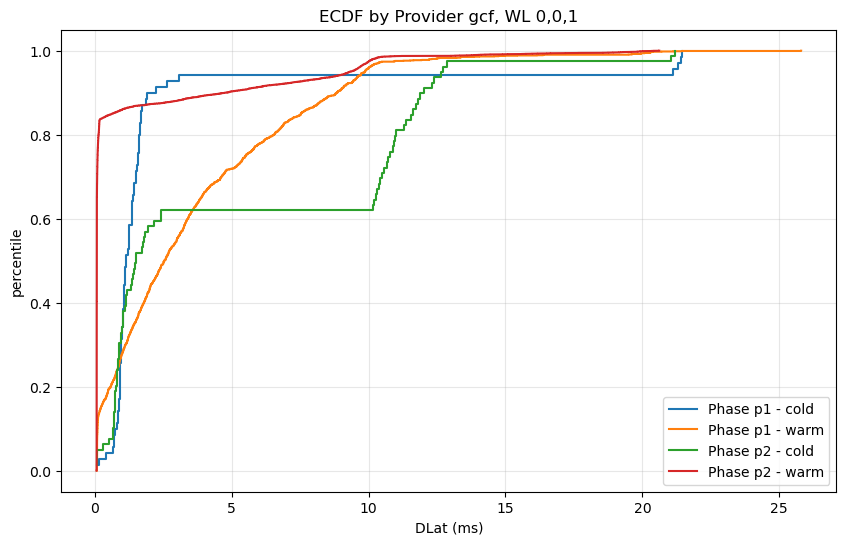

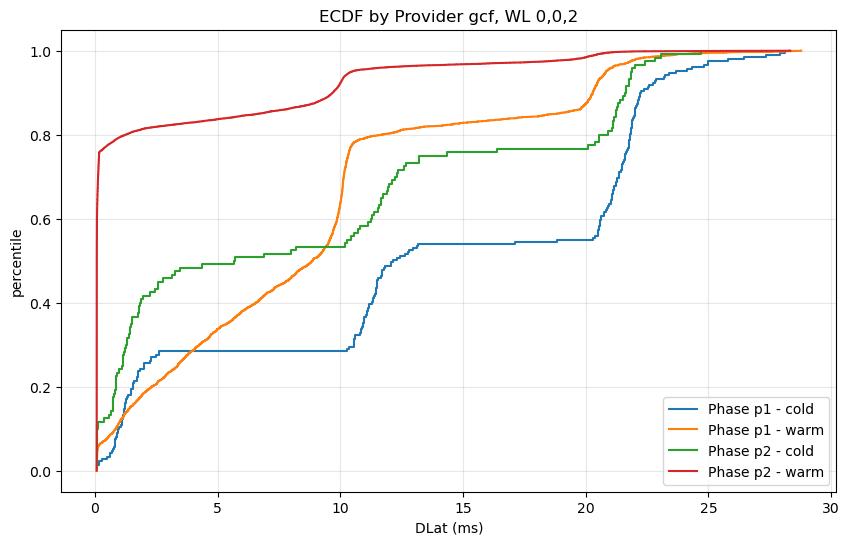

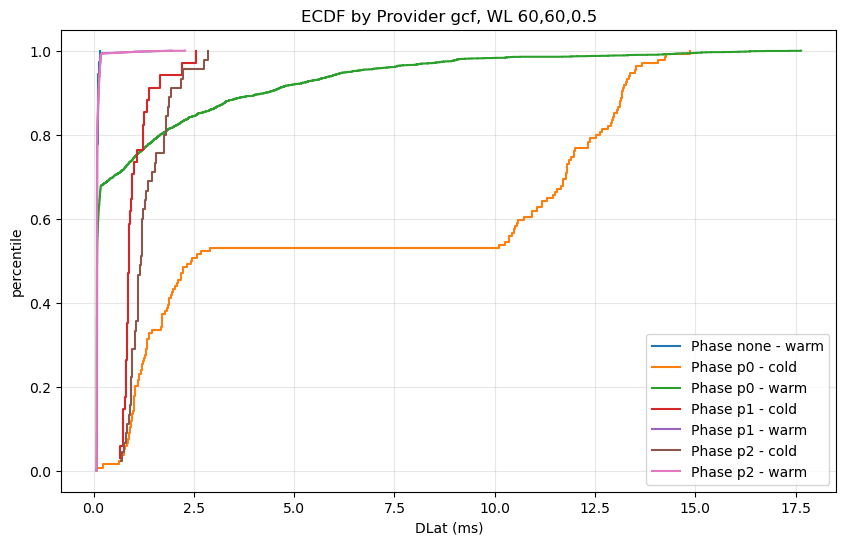

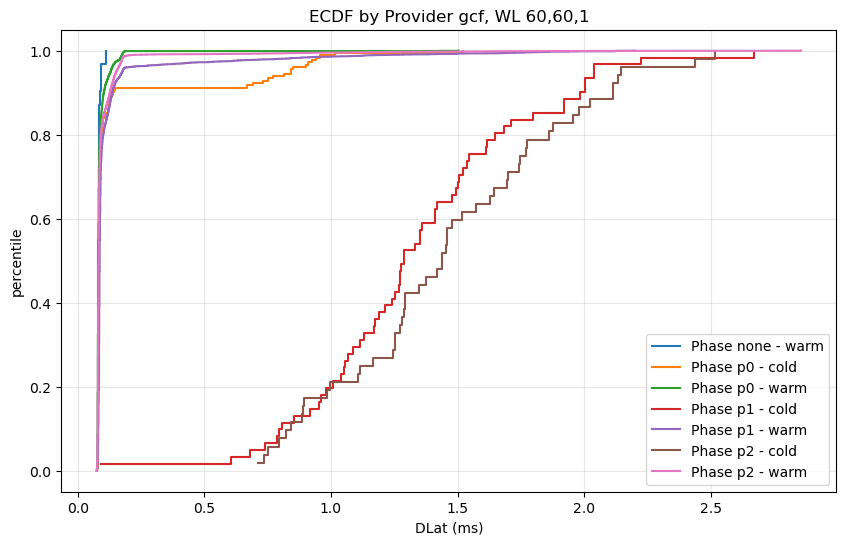

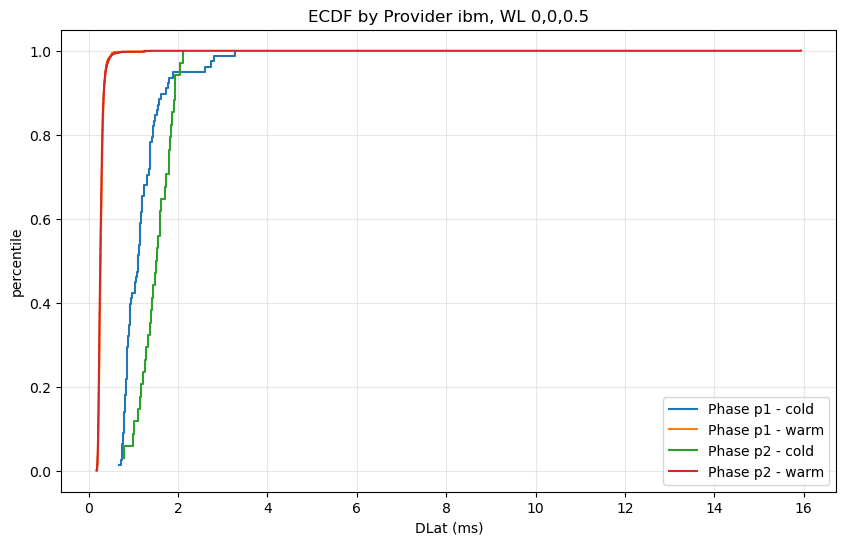

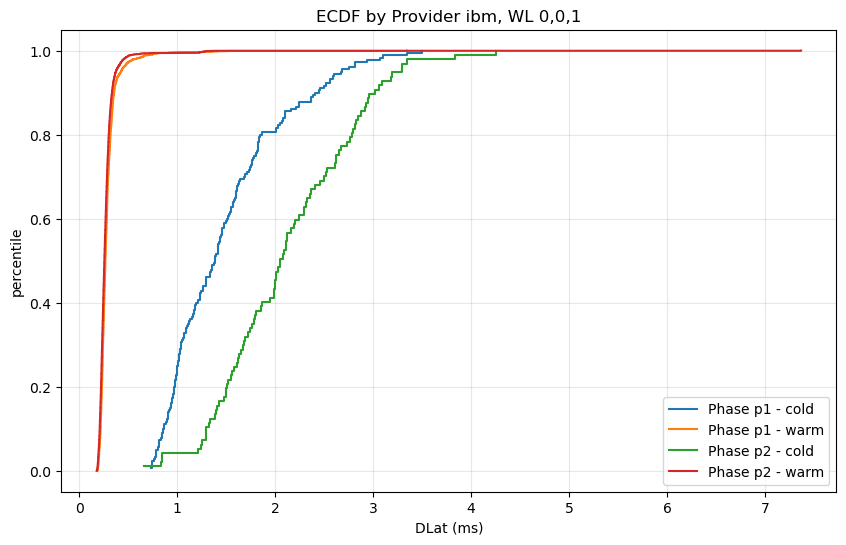

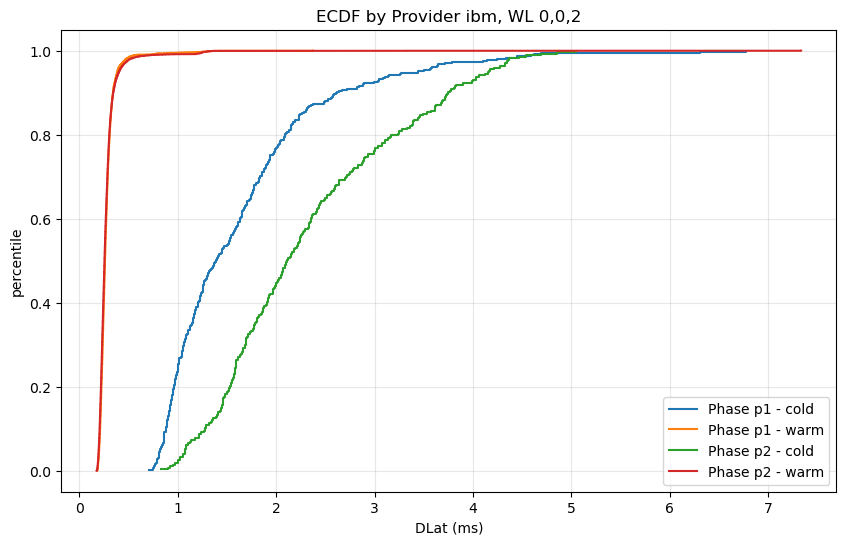

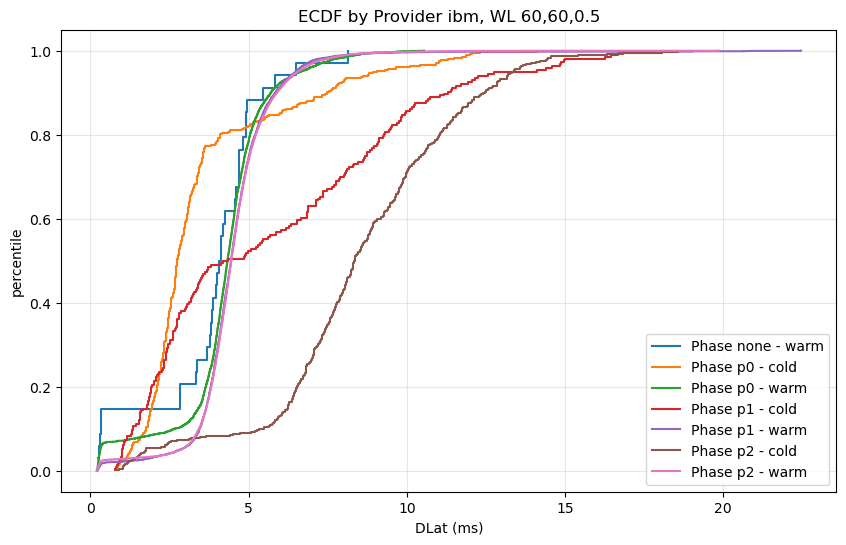

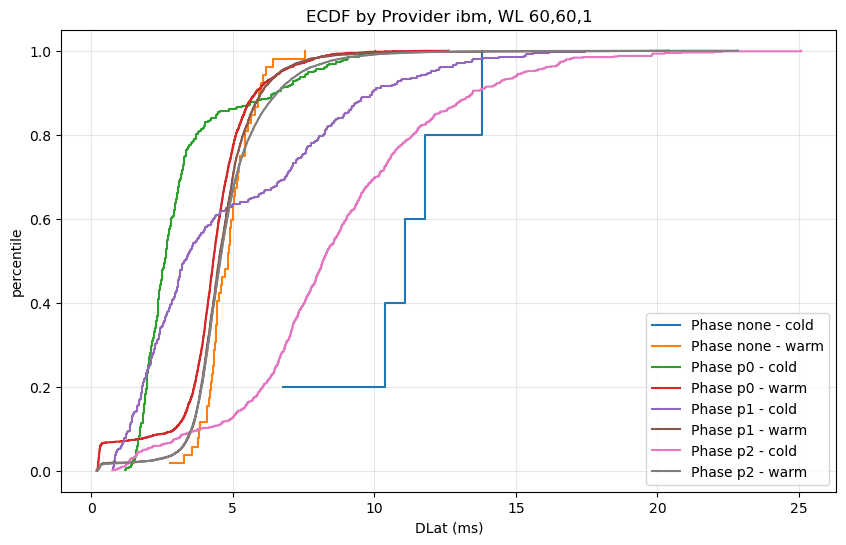

In [21]:
# ECDFs by Provider + WL, with cold/warm lines per Phase (DLat)
import duckdb
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

db_path = "full_data.duckdb"

conn = duckdb.connect(db_path)

try:
    plot_df = conn.execute("""
        SELECT DLat, Provider, WL, Phase, cold
        FROM full_data_enriched
        WHERE DLat IS NOT NULL
          AND Provider IS NOT NULL
          AND WL IS NOT NULL
          AND Phase IS NOT NULL
          AND cold IS NOT NULL
          AND RSuccessed = TRUE
    """).df()

    plot_df["dlat_ms"] = pd.to_numeric(plot_df["DLat"], errors="coerce")
    plot_df = plot_df[np.isfinite(plot_df["dlat_ms"])].copy()

    def ecdf(values):
        values = np.sort(values)
        y = np.arange(1, len(values) + 1) / len(values)
        return values, y

    for (provider, wl), group_df in plot_df.groupby(["Provider", "WL"], dropna=False):
        plt.figure(figsize=(10, 6))
        for phase in sorted(group_df["Phase"].unique()):
            phase_df = group_df.loc[group_df["Phase"] == phase]
            for cold_value, label_suffix in [(True, "cold"), (False, "warm")]:
                series = phase_df.loc[phase_df["cold"] == cold_value, "dlat_ms"].to_numpy()
                if len(series) == 0:
                    continue
                x, y = ecdf(series)
                plt.step(x, y, where="post", label=f"Phase {phase} - {label_suffix}")

        plt.xlabel("DLat (ms)")
        plt.ylabel("percentile")
        plt.title(f"ECDF by Provider {provider}, WL {wl}")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.show()
finally:
    conn.close()

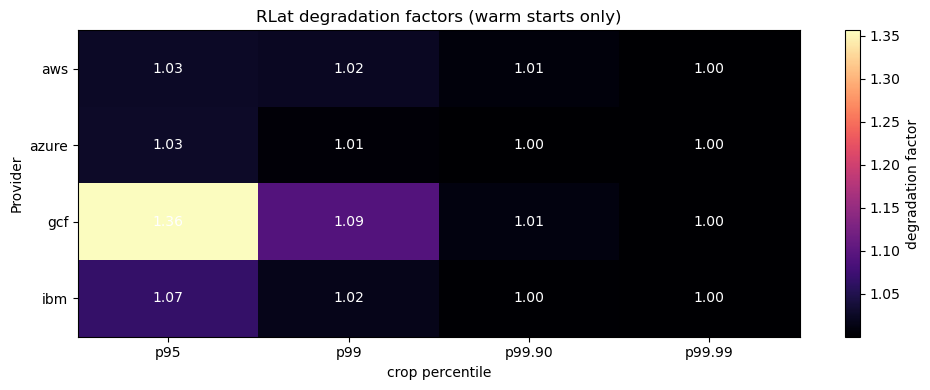

In [22]:
# Heatmap: RLat degradation factors by Provider (warm starts)
import duckdb
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

db_path = "full_data.duckdb"

conn = duckdb.connect(db_path)

try:
    df = conn.execute("""
        SELECT Provider, RLat, cold
        FROM full_data_enriched
        WHERE RLat IS NOT NULL
          AND Provider IS NOT NULL
          AND cold = FALSE
          AND RSuccessed = TRUE
    """).df()

    df["RLat"] = pd.to_numeric(df["RLat"], errors="coerce")
    df = df[np.isfinite(df["RLat"])].copy()

    thresholds = [0.95, 0.99, 0.999, 0.9999]
    providers = sorted(df["Provider"].unique())

    heatmap = np.zeros((len(providers), len(thresholds)))

    for i, provider in enumerate(providers):
        values = df.loc[df["Provider"] == provider, "RLat"].to_numpy()
        if len(values) == 0:
            heatmap[i, :] = np.nan
            continue

        overall_mean = np.mean(values)
        for j, q in enumerate(thresholds):
            cutoff = np.quantile(values, q)
            cropped = values[values <= cutoff]
            if len(cropped) == 0:
                heatmap[i, j] = np.nan
                continue
            cropped_mean = np.mean(cropped)
            heatmap[i, j] = overall_mean / cropped_mean

    plt.figure(figsize=(10, max(4, 0.4 * len(providers))))
    im = plt.imshow(heatmap, aspect="auto", cmap="magma")
    plt.colorbar(im, label="degradation factor")

    plt.xticks(range(len(thresholds)), [f"p{int(t*100)}" if t < 0.999 else f"p{t*100:.2f}" for t in thresholds])
    plt.yticks(range(len(providers)), [str(p) for p in providers])
    plt.xlabel("crop percentile")
    plt.ylabel("Provider")
    plt.title("RLat degradation factors (warm starts only)")

    for i in range(len(providers)):
        for j in range(len(thresholds)):
            val = heatmap[i, j]
            if np.isfinite(val):
                plt.text(j, i, f"{val:.2f}", ha="center", va="center", color="white")

    plt.tight_layout()
    plt.show()
finally:
    conn.close()

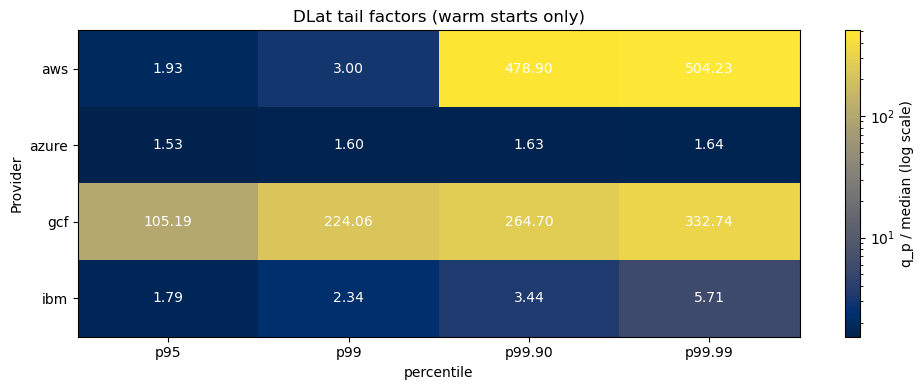

In [1]:
# Heatmap: DLat tail factors by Provider (warm starts)
import duckdb
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

db_path = "full_data.duckdb"

conn = duckdb.connect(db_path)

try:
    df = conn.execute("""
        SELECT Provider, DLat, cold
        FROM full_data_enriched
        WHERE DLat IS NOT NULL
          AND Provider IS NOT NULL
          AND cold = FALSE
          AND RSuccessed = TRUE
    """).df()

    df["DLat"] = pd.to_numeric(df["DLat"], errors="coerce")
    df = df[np.isfinite(df["DLat"])].copy()

    thresholds = [0.95, 0.99, 0.999, 0.9999]
    providers = sorted(df["Provider"].unique())

    heatmap = np.zeros((len(providers), len(thresholds)))

    for i, provider in enumerate(providers):
        values = df.loc[df["Provider"] == provider, "DLat"].to_numpy()
        if len(values) == 0:
            heatmap[i, :] = np.nan
            continue

        median = float(np.median(values))
        if not np.isfinite(median) or median <= 0:
            heatmap[i, :] = np.nan
            continue

        for j, q in enumerate(thresholds):
            q_val = float(np.quantile(values, q))
            heatmap[i, j] = (q_val / median) if np.isfinite(q_val) else np.nan

    plt.figure(figsize=(10, max(4, 0.4 * len(providers))))
    valid = np.isfinite(heatmap) & (heatmap > 0)
    if np.any(valid):
        vmin = np.nanmin(heatmap[valid])
        vmax = np.nanmax(heatmap[valid])
        im = plt.imshow(heatmap, aspect="auto", cmap="cividis", norm=LogNorm(vmin=vmin, vmax=vmax))
    else:
        im = plt.imshow(heatmap, aspect="auto", cmap="cividis")
    plt.colorbar(im, label="q_p / median (log scale)")

    plt.xticks(range(len(thresholds)), [f"p{int(t*100)}" if t < 0.999 else f"p{t*100:.2f}" for t in thresholds])
    plt.yticks(range(len(providers)), [str(p) for p in providers])
    plt.xlabel("percentile")
    plt.ylabel("Provider")
    plt.title("DLat tail factors (warm starts only)")

    for i in range(len(providers)):
        for j in range(len(thresholds)):
            val = heatmap[i, j]
            if np.isfinite(val):
                plt.text(j, i, f"{val:.2f}", ha="center", va="center", color="white")

    plt.tight_layout()
    plt.show()
finally:
    conn.close()

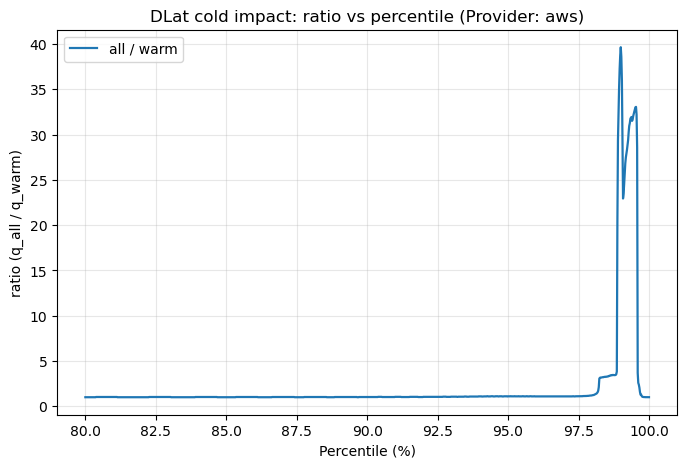

Provider: aws
Tail counts (>= percentile threshold):
p95.00: all=4841, warm=4776
p99.00: all=964, warm=952
p99.90: all=98, warm=95
p99.99: all=11, warm=10



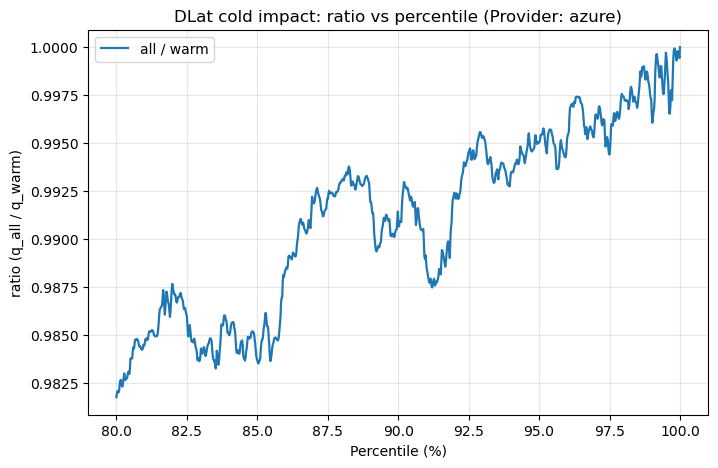

Provider: azure
Tail counts (>= percentile threshold):
p95.00: all=160, warm=133
p99.00: all=32, warm=27
p99.90: all=4, warm=3
p99.99: all=1, warm=1



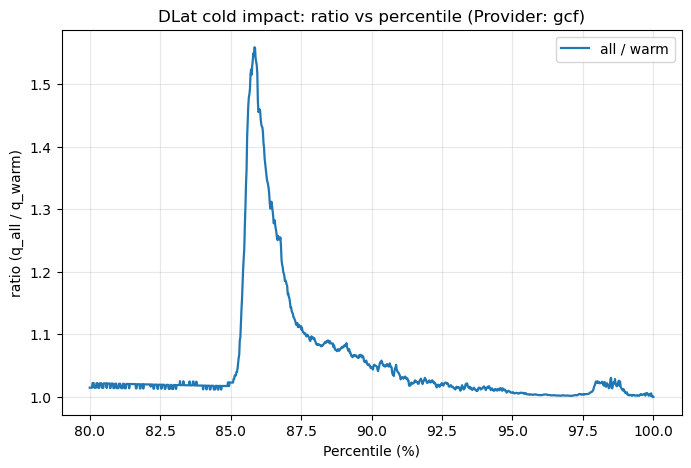

Provider: gcf
Tail counts (>= percentile threshold):
p95.00: all=4526, warm=4472
p99.00: all=906, warm=896
p99.90: all=91, warm=90
p99.99: all=10, warm=9



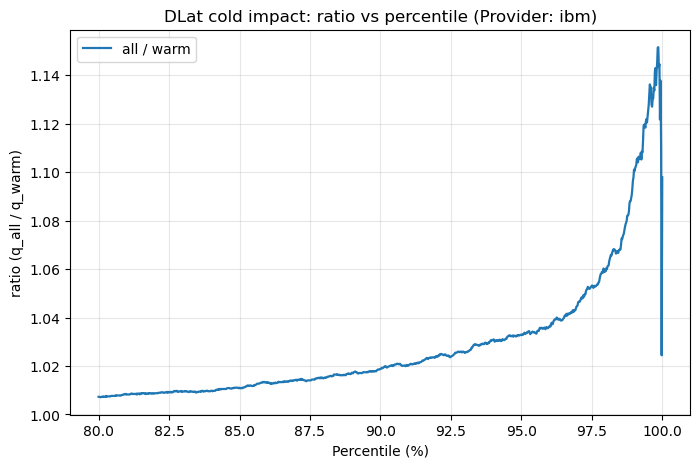

Provider: ibm
Tail counts (>= percentile threshold):
p95.00: all=4919, warm=4740
p99.00: all=985, warm=949
p99.90: all=99, warm=95
p99.99: all=10, warm=10



In [3]:
# Percentile curves: all vs warm ratio (DLat) per Provider
import duckdb
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

db_path = "full_data.duckdb"

conn = duckdb.connect(db_path)

try:
    df_all = conn.execute("""
        SELECT DLat, Provider
        FROM full_data_enriched
        WHERE DLat IS NOT NULL
          AND Provider IS NOT NULL
          AND RSuccessed = TRUE
    """).df()

    df_warm = conn.execute("""
        SELECT DLat, Provider
        FROM full_data_enriched
        WHERE DLat IS NOT NULL
          AND Provider IS NOT NULL
          AND CNew = 'Reused'
          AND RSuccessed = TRUE
    """).df()

    df_all["DLat"] = pd.to_numeric(df_all["DLat"], errors="coerce")
    df_warm["DLat"] = pd.to_numeric(df_warm["DLat"], errors="coerce")

    df_all = df_all[np.isfinite(df_all["DLat"])].copy()
    df_warm = df_warm[np.isfinite(df_warm["DLat"])].copy()

    providers = sorted(set(df_all["Provider"]).intersection(df_warm["Provider"]))
    if len(providers) == 0:
        print("No provider data available for percentile curves.")
    else:
        percentiles = np.linspace(0.80, 1.00, 1000)
        tail_percentiles = [0.95, 0.99, 0.999, 0.9999]

        for provider in providers:
            all_vals = df_all.loc[df_all["Provider"] == provider, "DLat"].to_numpy()
            warm_vals = df_warm.loc[df_warm["Provider"] == provider, "DLat"].to_numpy()

            if len(all_vals) == 0 or len(warm_vals) == 0:
                continue

            q_all = np.quantile(all_vals, percentiles)
            q_warm = np.quantile(warm_vals, percentiles)

            ratio = q_all / q_warm
            ratio = np.where(np.isfinite(ratio), ratio, np.nan)

            plt.figure(figsize=(8, 5))
            plt.plot(percentiles * 100.0, ratio, label="all / warm", linewidth=1.6)
            plt.xlabel("Percentile (%)")
            plt.ylabel("ratio (q_all / q_warm)")
            plt.title(f"DLat cold impact: ratio vs percentile (Provider: {provider})")
            plt.grid(True, alpha=0.3)
            plt.legend()
            plt.show()

            print(f"Provider: {provider}")
            print("Tail counts (>= percentile threshold):")
            for p in tail_percentiles:
                thr_all = np.quantile(all_vals, p)
                thr_warm = np.quantile(warm_vals, p)
                count_all = int(np.sum(all_vals >= thr_all))
                count_warm = int(np.sum(warm_vals >= thr_warm))
                print(f"p{p*100:.2f}: all={count_all}, warm={count_warm}")
            print()
finally:
    conn.close()

Provider: aws
 hour       n p50.0_count p95.0_count p99.0_count p99.9_count
    0     NaN        <NA>        <NA>        <NA>        <NA>
    1     NaN        <NA>        <NA>        <NA>        <NA>
    2     NaN        <NA>        <NA>        <NA>        <NA>
    3     NaN        <NA>        <NA>        <NA>        <NA>
    4     NaN        <NA>        <NA>        <NA>        <NA>
    5     NaN        <NA>        <NA>        <NA>        <NA>
    6     NaN        <NA>        <NA>        <NA>        <NA>
    7     NaN        <NA>        <NA>        <NA>        <NA>
    8     NaN        <NA>        <NA>        <NA>        <NA>
    9     NaN        <NA>        <NA>        <NA>        <NA>
   10     NaN        <NA>        <NA>        <NA>        <NA>
   11     NaN        <NA>        <NA>        <NA>        <NA>
   12     NaN        <NA>        <NA>        <NA>        <NA>
   13     NaN        <NA>        <NA>        <NA>        <NA>
   14     NaN        <NA>        <NA>        <NA>       

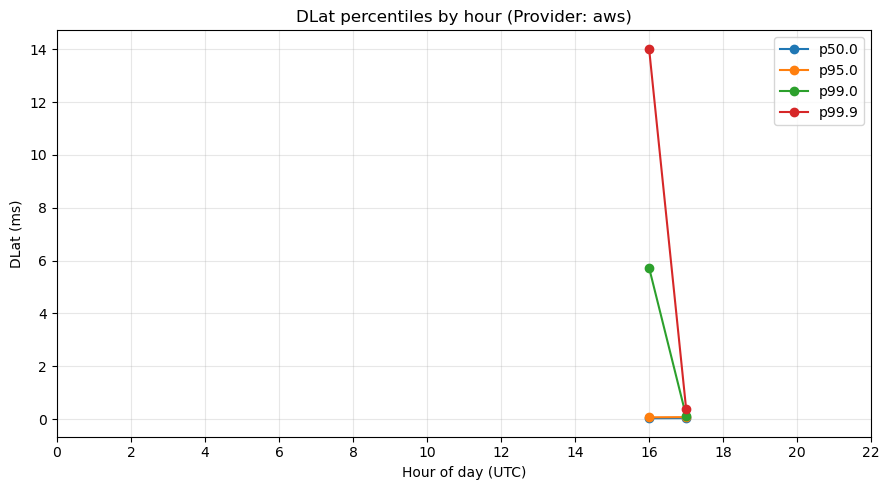

Provider: azure
 hour      n p50.0_count p95.0_count p99.0_count p99.9_count
    0    NaN        <NA>        <NA>        <NA>        <NA>
    1    NaN        <NA>        <NA>        <NA>        <NA>
    2    NaN        <NA>        <NA>        <NA>        <NA>
    3    NaN        <NA>        <NA>        <NA>        <NA>
    4    NaN        <NA>        <NA>        <NA>        <NA>
    5    NaN        <NA>        <NA>        <NA>        <NA>
    6    NaN        <NA>        <NA>        <NA>        <NA>
    7    NaN        <NA>        <NA>        <NA>        <NA>
    8    NaN        <NA>        <NA>        <NA>        <NA>
    9    NaN        <NA>        <NA>        <NA>        <NA>
   10    NaN        <NA>        <NA>        <NA>        <NA>
   11    NaN        <NA>        <NA>        <NA>        <NA>
   12    NaN        <NA>        <NA>        <NA>        <NA>
   13    NaN        <NA>        <NA>        <NA>        <NA>
   14    NaN        <NA>        <NA>        <NA>        <NA>
   15   

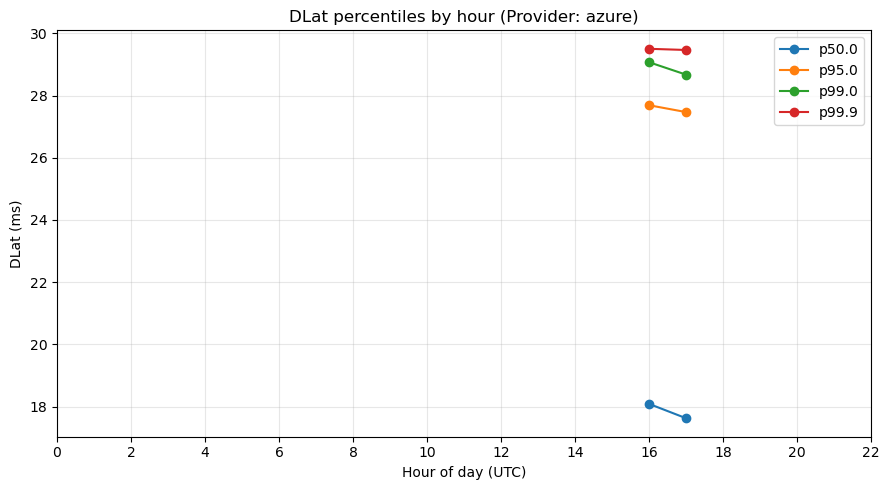

Provider: gcf
 hour       n p50.0_count p95.0_count p99.0_count p99.9_count
    0     NaN        <NA>        <NA>        <NA>        <NA>
    1     NaN        <NA>        <NA>        <NA>        <NA>
    2     NaN        <NA>        <NA>        <NA>        <NA>
    3     NaN        <NA>        <NA>        <NA>        <NA>
    4     NaN        <NA>        <NA>        <NA>        <NA>
    5     NaN        <NA>        <NA>        <NA>        <NA>
    6     NaN        <NA>        <NA>        <NA>        <NA>
    7     NaN        <NA>        <NA>        <NA>        <NA>
    8     NaN        <NA>        <NA>        <NA>        <NA>
    9     NaN        <NA>        <NA>        <NA>        <NA>
   10     NaN        <NA>        <NA>        <NA>        <NA>
   11     NaN        <NA>        <NA>        <NA>        <NA>
   12     NaN        <NA>        <NA>        <NA>        <NA>
   13     NaN        <NA>        <NA>        <NA>        <NA>
   14     NaN        <NA>        <NA>        <NA>       

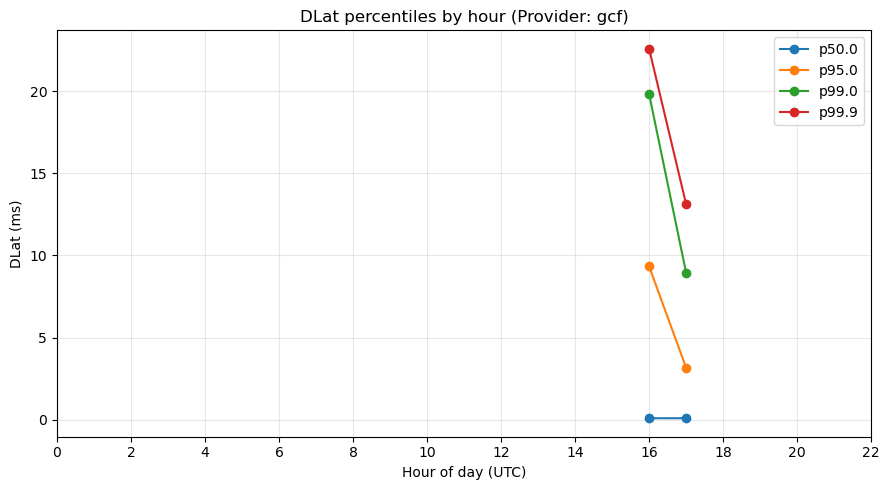

Provider: ibm
 hour       n p50.0_count p95.0_count p99.0_count p99.9_count
    0     NaN        <NA>        <NA>        <NA>        <NA>
    1     NaN        <NA>        <NA>        <NA>        <NA>
    2     NaN        <NA>        <NA>        <NA>        <NA>
    3     NaN        <NA>        <NA>        <NA>        <NA>
    4     NaN        <NA>        <NA>        <NA>        <NA>
    5     NaN        <NA>        <NA>        <NA>        <NA>
    6     NaN        <NA>        <NA>        <NA>        <NA>
    7     NaN        <NA>        <NA>        <NA>        <NA>
    8     NaN        <NA>        <NA>        <NA>        <NA>
    9     NaN        <NA>        <NA>        <NA>        <NA>
   10     NaN        <NA>        <NA>        <NA>        <NA>
   11     NaN        <NA>        <NA>        <NA>        <NA>
   12     NaN        <NA>        <NA>        <NA>        <NA>
   13     NaN        <NA>        <NA>        <NA>        <NA>
   14     NaN        <NA>        <NA>        <NA>       

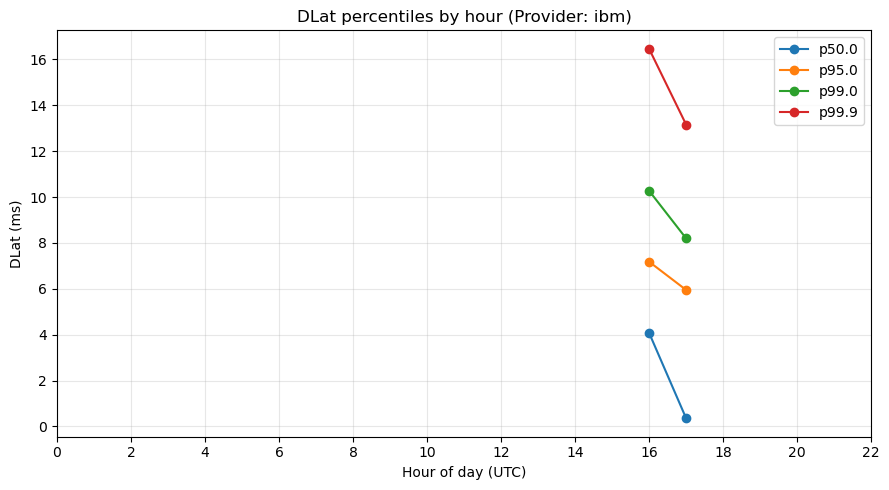

In [5]:
# Percentiles by hour over a day (DLat) per Provider
import duckdb
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

db_path = "full_data.duckdb"

percentiles = [0.50, 0.95, 0.99, 0.999]

conn = duckdb.connect(db_path)

try:
    df = conn.execute("""
        SELECT
            Provider,
            DLat,
            regexp_extract(sourceFile, 'result-([0-9]+)\\.csv', 1) AS ts_str
        FROM full_data_enriched
        WHERE Provider IS NOT NULL
          AND DLat IS NOT NULL
          AND RSuccessed = TRUE
          AND regexp_extract(sourceFile, 'result-([0-9]+)\\.csv', 1) <> ''
    """).df()

    df["dlat_ms"] = pd.to_numeric(df["DLat"], errors="coerce")
    df["ts_int"] = pd.to_numeric(df["ts_str"], errors="coerce")
    df = df[np.isfinite(df["dlat_ms"]) & np.isfinite(df["ts_int"])].copy()

    if df.empty:
        print("No rows with valid timestamps and DLat values.")
    else:
        # Assume timestamps are in seconds unless they look like milliseconds.
        is_ms = df["ts_int"] >= 1_000_000_000_000
        ts_ms = np.where(is_ms, df["ts_int"].to_numpy(), df["ts_int"].to_numpy() * 1000)
        df["timestamp"] = pd.to_datetime(ts_ms, unit="ms", utc=True)
        df["hour"] = df["timestamp"].dt.hour

        grouped = df.groupby(["Provider", "hour"], dropna=False)
        counts = grouped.size().rename("n").reset_index()

        quant = grouped["dlat_ms"].quantile(percentiles).reset_index()
        quant = quant.rename(columns={"level_2": "percentile", "dlat_ms": "value"})

        stats = quant.pivot_table(
            index=["Provider", "hour"],
            columns="percentile",
            values="value",
            aggfunc="first",
        ).reset_index()

        stats = stats.merge(counts, on=["Provider", "hour"], how="left")

        for provider in sorted(stats["Provider"].unique()):
            provider_stats = stats.loc[stats["Provider"] == provider].copy()
            provider_stats = provider_stats.sort_values("hour")

            # Ensure all 24 hours exist for plotting.
            full_hours = pd.DataFrame({"hour": list(range(24))})
            provider_stats = full_hours.merge(provider_stats, on="hour", how="left")
            provider_stats["Provider"] = provider

            print(f"Provider: {provider}")
            count_table = provider_stats[["hour", "n"]].copy()
            for p in percentiles:
                count_col = f"p{p*100:.1f}_count"
                count_table[count_col] = np.where(
                    np.isfinite(provider_stats["n"]),
                    np.ceil(provider_stats["n"] * p).astype("Int64"),
                    pd.NA,
                )
            print(count_table.to_string(index=False))
            print()

            plt.figure(figsize=(9, 5))
            for p in percentiles:
                label = f"p{p*100:.1f}"
                plt.plot(
                    provider_stats["hour"],
                    provider_stats[p],
                    marker="o",
                    linewidth=1.5,
                    label=label,
                )

            plt.xlabel("Hour of day (UTC)")
            plt.ylabel("DLat (ms)")
            plt.title(f"DLat percentiles by hour (Provider: {provider})")
            plt.xticks(range(0, 24, 2))
            plt.grid(True, alpha=0.3)
            plt.legend()
            plt.tight_layout()
            plt.show()
finally:
    conn.close()

In [ ]:
# Distinct GCF timestamps with human-readable time
import duckdb
import os
import numpy as np
import pandas as pd

db_path = "full_data.duckdb"

conn = duckdb.connect(db_path)

try:
    df_ts = conn.execute("""
        SELECT DISTINCT
            regexp_extract(sourceFile, 'result-([0-9]+)\\.csv', 1) AS distinct_timestamps
        FROM full_data_enriched
        WHERE provider = 'gcf'
          AND regexp_extract(sourceFile, 'result-([0-9]+)\\.csv', 1) <> ''
        ORDER BY distinct_timestamps
    """).df()

    df_ts["ts_int"] = pd.to_numeric(df_ts["distinct_timestamps"], errors="coerce")
    df_ts = df_ts[np.isfinite(df_ts["ts_int"])].copy()

    if df_ts.empty:
        print("No valid timestamps found for provider 'gcf'.")
    else:
        # Assume seconds unless they look like milliseconds.
        is_ms = df_ts["ts_int"] >= 1_000_000_000_000
        ts_ms = np.where(is_ms, df_ts["ts_int"].to_numpy(), df_ts["ts_int"].to_numpy() * 1000)
        df_ts["timestamp_utc"] = pd.to_datetime(ts_ms, unit="ms", utc=True)

        display_df = df_ts[["distinct_timestamps", "timestamp_utc"]].copy()
        print(display_df.to_string(index=False))
finally:
    conn.close()

distinct_timestamps                    timestamp_utc
      1567700478877 2019-09-05 16:21:18.877000+00:00
      1567700478889 2019-09-05 16:21:18.889000+00:00
      1567700478933 2019-09-05 16:21:18.933000+00:00
      1567700478942 2019-09-05 16:21:18.942000+00:00
      1567700478950 2019-09-05 16:21:18.950000+00:00
      1567702741049 2019-09-05 16:59:01.049000+00:00
      1567702741051 2019-09-05 16:59:01.051000+00:00
      1567702741097 2019-09-05 16:59:01.097000+00:00
      1567702741130 2019-09-05 16:59:01.130000+00:00
      1567702741149 2019-09-05 16:59:01.149000+00:00
      1567705006150 2019-09-05 17:36:46.150000+00:00
      1567705006167 2019-09-05 17:36:46.167000+00:00
      1567705006194 2019-09-05 17:36:46.194000+00:00
      1567705006197 2019-09-05 17:36:46.197000+00:00
      1567705006205 2019-09-05 17:36:46.205000+00:00
      1567705006222 2019-09-05 17:36:46.222000+00:00
      1567786590168 2019-09-06 16:16:30.168000+00:00
      1567786590179 2019-09-06 16:16:30.179000